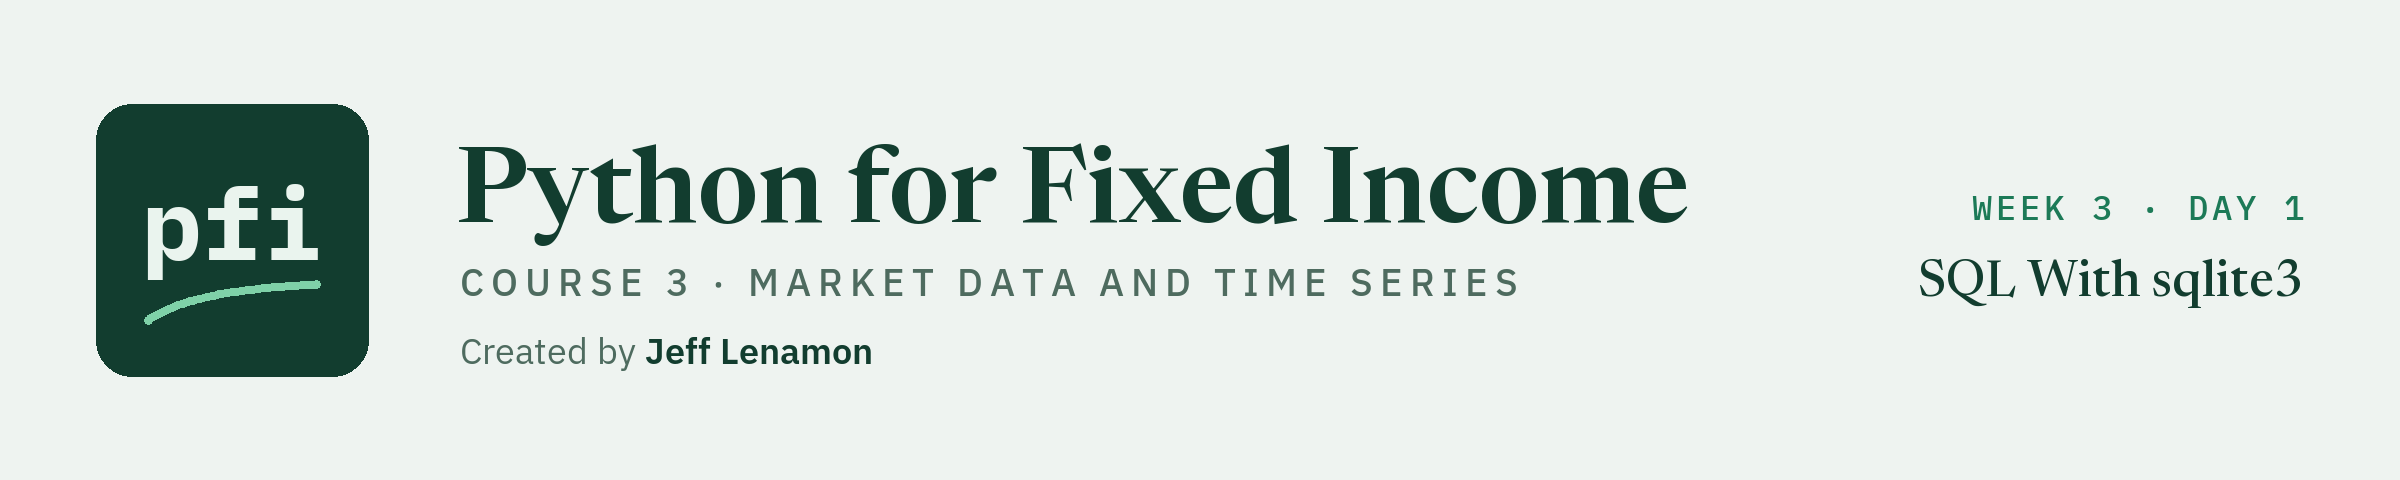

# SQL With sqlite3

Week 3, Day 1. The book in a database file: SQL with Python's own `sqlite3`, every query beside the pandas you trust, and an assert that proves the two return the same rows.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day1/11_sql_with_sqlite3.ipynb)

### The Desk Lead's Note

> The position file is moving into a database. Before any report comes out of it, give me the answers we already know, from SQL, each proved against pandas: the Energy bonds wider than 200 bp, the five largest positions, each sector's bonds, market value and average spread, the sectors holding at least 20 bonds, and the book's spread weighted by market value. Keep the queries where anyone can rerun them. Keep the database itself out of Git.

The issuers and holdings are invented; every number describes the data.
Nothing today goes to the network, so there is no key and no live cell.

**Every query sits beside the pandas you trust, and an assert proves they return the same rows.**

### Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py, its tests,
# and their Git history as notebook 10 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(11)

Work folder pfi_course3_11_k4w7q2xr: 10 data files, Course 2's bondmath.py, marketdata.py as notebook 10 left it, 10 commits, tagged week1 and week2


### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........................................                               [100%]
42 passed in 0.50s



### Imports and the Holdings File

Q. What is in the book?

In [3]:
import importlib

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
import bondmath
import marketdata as md

In [4]:
# the September book: one row per bond, OAS in bp, market value in dollars
holdings = pd.read_csv('holdings.csv')
print(f"{len(holdings)} bonds as of {holdings.loc[0, 'as_of_date']}, {holdings.shape[1]} columns")

200 bonds as of 2026-09-30, 19 columns


## 11.1 Why SQL, and Why Assistants Write So Much of It

Security masters, positions and trades often live in a **database**: named **tables**, one row per record, the shape of a CSV file.
**SQL** is the language a program uses to ask a database for rows, and a request is a **query**.

![One desk question in two languages, clause by clause. SELECT cusip, issuer, oas beside the pandas column list; FROM holdings beside the DataFrame holdings; WHERE sector = ? AND oas > ? beside the mask; ORDER BY oas DESC beside sort_values with ascending False; LIMIT ? beside head. Under the question marks, the values Energy, 200 and 5 travel separately](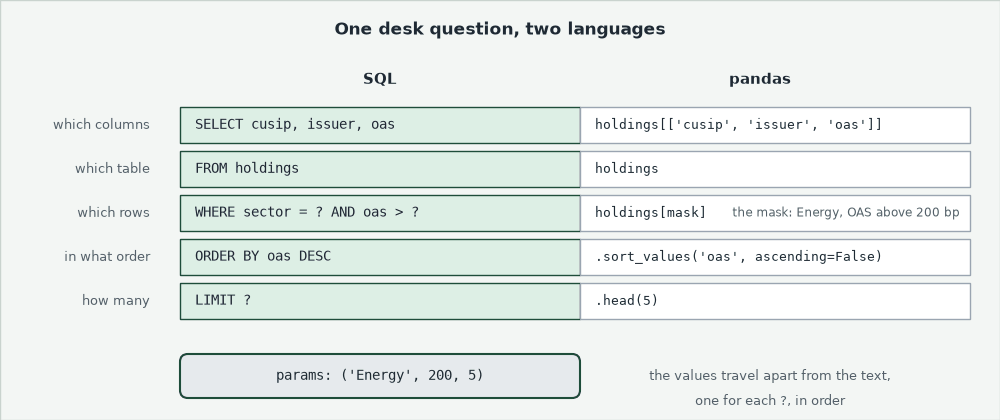)

A query names the result you want, clause by clause; the database works out how to get it.
Assistants write SQL readily, and their SQL runs whether or not it is right.
So every query today gets a pandas twin.

**SQL names the result you want, clause by clause; pandas is the answer key.**

## 11.2 `sqlite3`: a Database in One File

The databases a desk reads usually run as a server you log in to.
**SQLite** is a whole database in one file, with no server and no password, and Python ships with it.

### Which SQLite?

In [5]:
# Python's own SQLite module
import sqlite3

# the SQLite library inside this Python
print('SQLite', sqlite3.sqlite_version)

SQLite 3.50.4


### Two Lines Load a CSV

`sqlite3.connect(path)` opens the file, making it if it is missing, and returns a **connection**.
`closing()` from `contextlib` closes the file at the end of the `with` block; `sqlite3`'s own `with` does not.

In [6]:
# a database file in the work folder, made on first connect
from contextlib import closing

db_path = work / 'course3.db'
with closing(sqlite3.connect(db_path)) as connection:
    # the DataFrame to a table named holdings, replacing any table of that name
    holdings.to_sql('holdings', connection, if_exists='replace', index=False)
    # COUNT(*) counts rows; fetchone() reads the answer's one row, [0] its one value
    count = connection.execute('SELECT COUNT(*) FROM holdings').fetchone()[0]
print(count, 'rows in the table,', len(holdings), 'in the file')

200 rows in the table, 200 in the file


### Is It Text?

Q. A CSV is text. What is the database file?

In [7]:
# the first 16 bytes of each file; b'...' marks raw bytes
print((work / 'holdings.csv').read_bytes()[:16])
print(db_path.read_bytes()[:16])

b'as_of_date,cusip'
b'SQLite format 3\x00'


> STORY: The database you already have. SQLite's documentation calls it a database in "a single disk file" that can be copied from one machine to another, and says it is likely used more than all other database engines combined, in every smartphone among them. Every SQLite file begins with the 16 bytes you just printed. Sources: SQLite, "Single-file Cross-platform Database", https://www.sqlite.org/onefile.html; "Most Widely Deployed and Used Database Engine", https://www.sqlite.org/mostdeployed.html; "Database File Format", https://www.sqlite.org/fileformat.html (all read 2026-10-04).

The CSV opens with its header row.
The database opens with SQLite's own label: a binary file, read through `sqlite3`, never in a text editor.

**Two lines put a CSV into a database file, and `COUNT(*)` reads its rows back: 200, the same as the file.**

## 11.3 `load_tables`

Two lines worked for one file.
The book has five, and a load should prove itself every time.

![What load_tables does with each file. holdings.csv, 200 rows, goes to a name check: a plain name passes, anything else raises ValueError. Then to_sql writes the table, replacing any old one, never appending. Then a count query reads the row count back from the database. 200 equals 200, so on to the next file; a count that differs raises RuntimeError](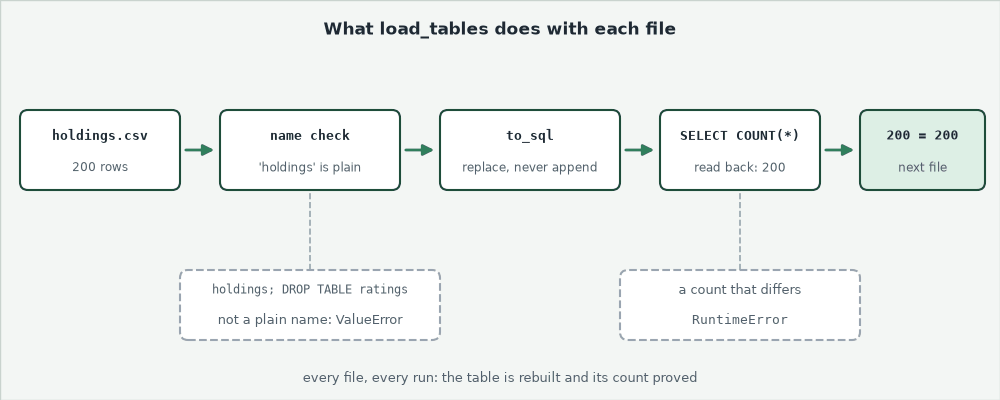)

### Append It

`str.isidentifier()` is True for a plain name: letters, digits and underscores.
`connection.commit()` saves the writes to the file.

In [8]:
%%writefile -a marketdata.py


import sqlite3  # a database in one file, from day 11
from contextlib import closing  # closes a connection at the end of a with block, from day 11


def load_tables(db_path: Path, tables: dict[str, Path]) -> dict[str, int]:
    """Write each CSV file to a table of the SQLite database at db_path, and return each table's row count.

    Units: unchanged; dates stay ISO text (YYYY-MM-DD), which SQLite sorts and compares in date order.
    Convention: tables maps a table name to a CSV path; an existing table of that name is replaced. Each
    count is read back from the database with SELECT COUNT(*) and checked against the CSV's rows.
    Raises ValueError for a table name that is not a plain identifier (letters, digits, underscore), and
    RuntimeError if a table's count differs from its CSV's.
    """
    counts = {}
    # sqlite3's own `with` commits but does not close, so closing() closes the file at the end
    with closing(sqlite3.connect(db_path)) as connection:
        for name, csv_path in tables.items():
            # a table name cannot be a ? parameter, so only plain names are allowed
            if not name.isidentifier():
                raise ValueError(f"table name {name!r} must be letters, digits, and underscores")
            frame = pd.read_csv(csv_path)
            frame.to_sql(name, connection, if_exists="replace", index=False)
            connection.commit()
            # read the count back from the database and check it
            count = connection.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]
            if count != len(frame):
                raise RuntimeError(f"table {name} has {count} rows but {Path(csv_path).name} has {len(frame)}")
            counts[name] = count
    return counts

Appending to marketdata.py


### Five Tables

In [9]:
# reload: the file on disk gained load_tables
importlib.reload(md)
TABLES = {'holdings': 'holdings.csv', 'issuers': 'issuers.csv', 'ratings': 'ratings.csv',
          'benchmark': 'benchmark.csv', 'trades': 'trade_blotter.csv'}
table_counts = md.load_tables(db_path, TABLES)
table_counts

{'holdings': 200,
 'issuers': 150,
 'ratings': 18,
 'benchmark': 821,
 'trades': 374}

Each count was read back from the database and matched its file.
`course3.db` lives in the work folder and is rebuilt on every run.
The Treasury and spreads tables join tomorrow, in notebook 12.
A table name goes into the SQL text itself, so only plain names pass; 11.5 shows what pasted text can do.

### The Test

In SQL, `;` ends one command and `DROP TABLE` deletes a table: the refused name carries a second command.

In [10]:
%%writefile -a test_marketdata.py


def test_load_tables_counts(tmp_path):
    counts = md.load_tables(tmp_path / "course3.db", {"holdings": HERE / "holdings.csv", "ratings": HERE / "ratings.csv"})
    assert counts == {"holdings": 200, "ratings": 18}
    # loading again replaces the tables instead of adding rows
    assert md.load_tables(tmp_path / "course3.db", {"holdings": HERE / "holdings.csv"}) == {"holdings": 200}
    with pytest.raises(ValueError):
        md.load_tables(tmp_path / "course3.db", {"holdings; DROP TABLE ratings": HERE / "holdings.csv"})

Appending to test_marketdata.py


In [11]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........................................                              [100%]
43 passed in 0.50s



**`load_tables` writes each CSV to a table and refuses to finish unless every count matches its file.**

## 11.4 `SELECT`, `WHERE`, `ORDER BY`, `LIMIT`, Each Beside pandas

The tables are in; now ask them questions.

### `run_query`

`pd.read_sql_query(sql, connection, params=)` runs a query and returns its rows as a DataFrame.

In [12]:
%%writefile -a marketdata.py


def run_query(db_path: Path, sql: str, params: tuple = ()) -> pd.DataFrame:
    """Run one SQL query against the SQLite database at db_path and return the result.

    Units: as stored. Convention: values go in through ? parameters (`params`), never pasted into the SQL
    text with an f-string. The connection is closed when the query is done.
    Raises FileNotFoundError if db_path does not exist (sqlite3 would otherwise create an empty database).
    """
    if not Path(db_path).is_file():
        raise FileNotFoundError(f"no database file {Path(db_path).name}")
    with closing(sqlite3.connect(db_path)) as connection:
        return pd.read_sql_query(sql, connection, params=params)

Appending to marketdata.py


![Two results side by side. The SQL result in the order the query gave, the pandas result in another order. Both are sorted by the key, cusip, the index is reset, and the columns are lined up in the same order. Then compared cell by cell: text and counts exactly, decimals within 1e-12 relative. Same rows, any order](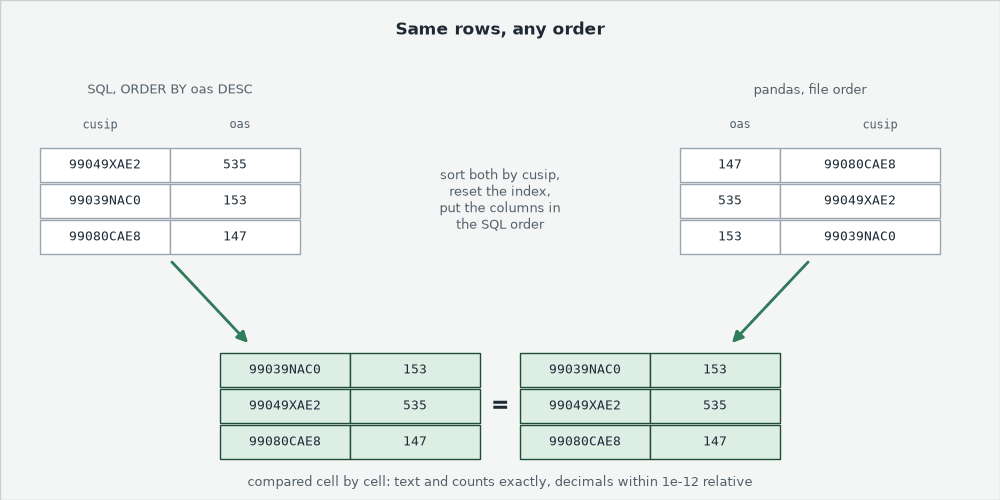)

A query returns its rows in its own order, and pandas keeps the file's.
The twin's proof lines both up before it compares.

### `assert_same_rows`

`pd.testing.assert_frame_equal` is notebook 10's check of two tables; `check_dtype=False` lets a column of whole numbers equal one of decimals, and `rtol` and `atol` allow the last digits a sum in another order can move.

In [13]:
%%writefile -a marketdata.py


def assert_same_rows(left: pd.DataFrame, right: pd.DataFrame, sort_by: list[str]) -> None:
    """Check that two tables hold the same rows, in any order: a SQL result against its pandas equivalent.

    Units: unchanged. Convention: the same column names; both sorted by `sort_by`, index reset, columns in
    left's order; text and whole numbers equal exactly, floats within rtol=1e-12 and atol=1e-9 (SQLite and
    pandas may add in a different order). An integer column on one side may be a float column on the other.
    Raises AssertionError with pandas' message on the first difference.
    """
    # the same columns, whatever their order
    if set(left.columns) != set(right.columns):
        raise AssertionError(f"columns differ: left only {sorted(set(left.columns) - set(right.columns))}, "
                             f"right only {sorted(set(right.columns) - set(left.columns))}")
    # the same order of rows and columns on both sides
    left_sorted = left.sort_values(sort_by).reset_index(drop=True)
    right_sorted = right[list(left.columns)].sort_values(sort_by).reset_index(drop=True)
    pd.testing.assert_frame_equal(left_sorted, right_sorted, check_dtype=False, rtol=1e-12, atol=1e-9)

Appending to marketdata.py


### `SELECT` and `FROM`

Q. Four columns of every bond, from SQL and from pandas?

In [14]:
# reload: the file on disk gained run_query and assert_same_rows
importlib.reload(md)
# SELECT names the columns, FROM names the table
from_sql = md.run_query(db_path, 'SELECT cusip, issuer, sector, oas FROM holdings')
from_pandas = holdings[['cusip', 'issuer', 'sector', 'oas']]
# silent when the rows agree; an AssertionError when they do not
md.assert_same_rows(from_sql, from_pandas, sort_by=['cusip'])
print('SQL and pandas: the same', len(from_sql), 'rows')
from_sql.head(3)

SQL and pandas: the same 200 rows


,cusip,issuer,sector,oas
0,99080CAE8,Bezane Finance,Financials,147
1,99049XAE2,Bezamyth Machinery,Industrials,535
2,99039NAC0,Bezoquil Freight,Transportation,153


`SELECT *` returns every column.

### `WHERE`

Q. Which Energy bonds are wider than 200 bp?

A `?` marks where a value goes, and the values travel in a tuple, in order; 11.5 shows why.

In [15]:
# WHERE keeps the rows that pass; AND needs both tests; a single = tests equality
sql = 'SELECT cusip, issuer, oas FROM holdings WHERE sector = ? AND oas > ?'
from_sql = md.run_query(db_path, sql, ('Energy', 200))
mask = (holdings['sector'] == 'Energy') & (holdings['oas'] > 200)
md.assert_same_rows(from_sql, holdings.loc[mask, ['cusip', 'issuer', 'oas']], sort_by=['cusip'])
from_sql

,cusip,issuer,oas
0,99145PAA0,Praximer Energy,468
1,99074WAB8,Wyxundra Energy,532
2,99074WAD4,Wyxundra Energy,332


`OR` keeps a row that passes either test.

**Excel side by side.** The sheet: cusip in A, issuer in B, sector in C, rating in D, oas in E, market_value in F, the 200 bonds in rows 2 to 201.

<table align="left">
<tr><th align="left">Job</th><th align="left">SQL</th><th align="left">pandas</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Energy wider than 200 bp</td><td align="left"><code>WHERE sector = ? AND oas &gt; ?</code></td><td align="left">the mask</td><td align="left"><code>=FILTER(A2:A201,(C2:C201="Energy")*(E2:E201&gt;200))</code></td><td align="left">the same 3 cusips</td></tr>
</table>
<br clear="left">

`*` multiplies two TRUE or FALSE tests: 1 only when both are TRUE, so it works as AND.

### The Energy Bonds on a Chart

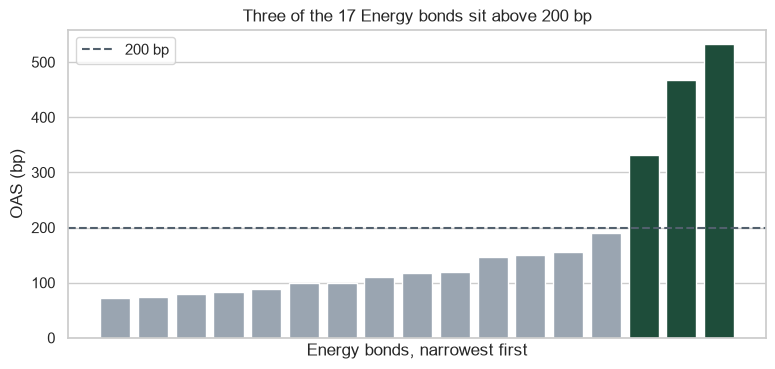

In [16]:
# the 17 Energy bonds, narrowest first; the three the query found in dark green
energy = holdings[holdings['sector'] == 'Energy'].sort_values('oas')
colours = ['#1E4D3A' if oas > 200 else '#9AA5B1' for oas in energy['oas']]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(len(energy)), energy['oas'], color=colours)
ax.axhline(200, color='#52606D', linestyle='--', label='200 bp')
ax.set_xticks([])  # an empty list: no labels under the bars
ax.set_title('Three of the 17 Energy bonds sit above 200 bp')
ax.set_xlabel('Energy bonds, narrowest first')
ax.set_ylabel('OAS (bp)')
ax.legend(loc='upper left')
plt.show()

SQL, pandas and Excel return the same three bonds.

### `ORDER BY` and `LIMIT`

Q. The five largest positions by market value?

In [17]:
# ORDER BY sorts, DESC largest first; LIMIT keeps the first rows
sql = 'SELECT cusip, issuer, market_value FROM holdings ORDER BY market_value DESC LIMIT ?'
top_five = md.run_query(db_path, sql, (5,))
from_pandas = holdings.sort_values('market_value', ascending=False).head(5)
md.assert_same_rows(top_five, from_pandas[['cusip', 'issuer', 'market_value']], sort_by=['cusip'])
# assert_same_rows ignores order on purpose, so check the order too
assert top_five['cusip'].tolist() == from_pandas['cusip'].tolist()
top_five.style.hide(axis='index').format({'market_value': '{:,.2f}'})

cusip,issuer,market_value
99080CAE8,Bezane Finance,"5,435,500.00"
99021VAC2,Feskundra Systems,"5,422,700.00"
99076YAC0,Lorvebran Paper,"5,287,462.50"
99129ZAB6,Zarizal Industrial,"5,253,950.00"
99144OAF3,Lorvellix Energy,"5,241,650.00"


`(5,)` is a tuple of one value: the comma makes it a tuple.
Without `ORDER BY` a database promises no order at all.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">SQL</th><th align="left">pandas</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Five largest by market value</td><td align="left"><code>ORDER BY market_value DESC LIMIT ?</code></td><td align="left"><code>.sort_values(ascending=False).head(5)</code></td><td align="left"><code>=TAKE(SORTBY(A2:A201,F2:F201,-1),5)</code></td><td align="left">the same 5 cusips, in order</td></tr>
</table>
<br clear="left">

### Dates Are Text

In [18]:
# SQLite has no date type: maturity is ISO text, YYYY-MM-DD
sql = 'SELECT cusip, issuer, maturity FROM holdings WHERE maturity < ? ORDER BY maturity'
early = md.run_query(db_path, sql, ('2030-01-01',))
print(len(early), 'bonds mature before 2030, the first on', early.loc[0, 'maturity'])
print(type(early.loc[0, 'maturity']))

34 bonds mature before 2030, the first on 2027-10-02
<class 'str'>


ISO text puts the year first, so text order is date order; notebook 12 shows when that breaks.

**Each clause has a pandas twin, and `assert_same_rows` proves every pair: the note's first two asks come straight from the database.**

## 11.5 Parameters With `?`

Every value so far travelled in a tuple.
Here is what happens when a value is pasted into the SQL text instead.

### A Ticker With a Quote

In [19]:
# a ticker with a quote in it; no bond in the book has it
ticker = "O'BRN"
# the value pasted into the SQL text with an f-string
pasted = md.run_query(db_path, f"SELECT cusip FROM holdings WHERE ticker = '{ticker}'")

DatabaseError: Execution failed on sql 'SELECT cusip FROM holdings WHERE ticker = 'O'BRN'': near "BRN": syntax error

No bond has that ticker, yet the query never ran.
The quote in `O'BRN` closed the SQL text early, and SQLite could not read the rest.

### The Same Question, as a Parameter

In [20]:
# the ? carries the value apart from the SQL text
as_parameter = md.run_query(db_path, 'SELECT cusip FROM holdings WHERE ticker = ?', (ticker,))
print(len(as_parameter), 'bonds, and no error')

0 bonds, and no error


**Predict 1**

Q. Another value, pasted the same way: `NONE' OR '1'='1`. What comes back?

A) no rows: no bond has that ticker
B) a syntax error, as `O'BRN` gave
C) every bond in the book

### Both Routes

In [21]:
# the same question, both routes
value = "NONE' OR '1'='1"
pasted = md.run_query(db_path, f"SELECT cusip FROM holdings WHERE ticker = '{value}'")
as_parameter = md.run_query(db_path, 'SELECT cusip FROM holdings WHERE ticker = ?', (value,))
print(f'pasted into the SQL: {len(pasted)} rows; as a parameter: {len(as_parameter)} rows')

pasted into the SQL: 200 rows; as a parameter: 0 rows


![Left, the value pasted into the SQL text: WHERE ticker = 'NONE' OR '1'='1'. Its quotes pair up so that ticker = 'NONE' is one test and '1'='1' another, joined by OR; '1'='1' is true on every row, so all 200 bonds come back. Right, the ? route: the SQL text WHERE ticker = ? and the value sent apart, compared whole with each ticker, 0 rows](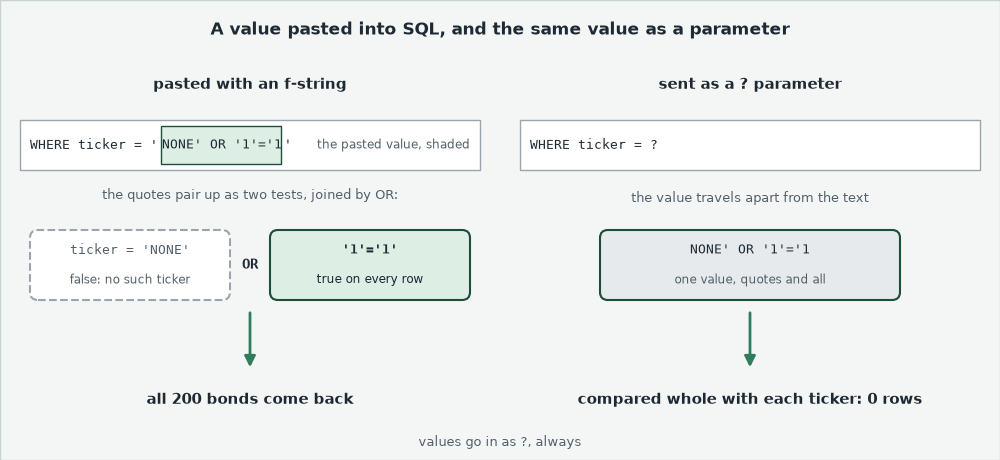)

C.
The pasted value closed the quote and added a second test, `'1'='1'`, true for every row.
A value that rewrote the question is **SQL injection**.
The rule: values go in as `?`, always.
A table name cannot be a `?`, so `load_tables` checks each name before it goes into the text.

### The Test

`build_database` makes a small database for the tests that follow.

In [22]:
%%writefile -a test_marketdata.py


def build_database(folder: Path) -> Path:
    """course3.db in `folder`, holding the holdings and ratings tables from this folder's CSV files."""
    db_path = folder / "course3.db"
    md.load_tables(db_path, {"holdings": HERE / "holdings.csv", "ratings": HERE / "ratings.csv"})
    return db_path


def test_run_query_params(tmp_path):
    db_path = build_database(tmp_path)
    holdings = pd.read_csv(HERE / "holdings.csv")
    result = md.run_query(db_path, "SELECT COUNT(*) AS bonds FROM holdings WHERE sector = ?", ("Energy",))
    assert result.loc[0, "bonds"] == (holdings["sector"] == "Energy").sum()
    # a value with a quote in it is just a value when it goes in as a parameter
    quoted = md.run_query(db_path, "SELECT * FROM holdings WHERE ticker = ?", ("O'BRN",))
    assert len(quoted) == 0
    with pytest.raises(FileNotFoundError):
        md.run_query(tmp_path / "missing.db", "SELECT 1")

Appending to test_marketdata.py


In [23]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

............................................                             [100%]
44 passed in 0.50s



**A pasted value can break a query or quietly rewrite it; a `?` parameter is only ever a value.**

## 11.6 `GROUP BY` With `COUNT`, `SUM`, `AVG`, and `HAVING`

The note's next ask is a summary: one row per sector.

### By Sector

`GROUP BY sector` makes one row per sector, and `COUNT(*)`, `SUM()` and `AVG()` work over each sector's bonds.
`AS` names a result column.

In [24]:
# one row per sector: its bonds, market value in dollars, and simple average OAS in bp
sql = '''SELECT sector, COUNT(*) AS bonds, SUM(market_value) AS market_value, AVG(oas) AS avg_oas
         FROM holdings GROUP BY sector ORDER BY market_value DESC'''
by_sector_sql = md.run_query(db_path, sql)
# Course 1's Styler: .bar draws a bar in each market value cell, sized by the value
by_sector_sql.style.hide(axis='index').format(
    {'market_value': '{:,.2f}', 'avg_oas': '{:.2f}'}).bar(subset=['market_value'], color='#9AA5B1')

sector,bonds,market_value,avg_oas
Materials,26,"71,701,617.50",182.42
Financials,26,"68,219,672.50",172.31
Consumer,26,"56,629,597.50",218.88
Telecom,21,"55,848,270.00",182.38
Industrials,20,"52,540,745.00",220.55
Transportation,20,"48,822,897.50",126.50
Health Care,20,"38,908,187.50",141.75
Energy,17,"38,830,005.00",171.59
Technology,12,"30,311,760.00",298.17
Utilities,12,"29,006,462.50",177.92


In [25]:
# Course 1's named agg: new column = (column, function)
by_sector_pandas = holdings.groupby('sector').agg(
    bonds=('cusip', 'count'), market_value=('market_value', 'sum'), avg_oas=('oas', 'mean'))
md.assert_same_rows(by_sector_sql, by_sector_pandas.reset_index(), sort_by=['sector'])
print(f"{by_sector_sql['bonds'].sum()} bonds, {by_sector_sql['market_value'].sum():,.2f} dollars")

200 bonds, 490,819,215.00 dollars


**Excel side by side.** A pivot table groups the same sheet.
Insert, then PivotTable, with `sector` in Rows and `cusip` (Count), `market_value` (Sum) and `oas` (Average) in Values.
The formulas need a summary block, the ten sectors in J2:J11.

<table align="left">
<tr><th align="left">Job</th><th align="left">SQL</th><th align="left">pandas</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">One row per sector</td><td align="left"><code>GROUP BY sector</code></td><td align="left"><code>.groupby('sector').agg(...)</code></td><td align="left">the pivot table</td><td align="left">10 rows; Grand Total 200 bonds, 490,819,215.0, 185.75</td></tr>
<tr><td align="left">Bonds per sector</td><td align="left"><code>COUNT(*)</code></td><td align="left"><code>('cusip', 'count')</code></td><td align="left"><code>=COUNTIFS($C$2:$C$201,J2)</code></td><td align="left">Energy 17</td></tr>
<tr><td align="left">Market value</td><td align="left"><code>SUM(market_value)</code></td><td align="left"><code>('market_value', 'sum')</code></td><td align="left"><code>=SUMIFS($F$2:$F$201,$C$2:$C$201,J2)</code></td><td align="left">Energy 38,830,005.0</td></tr>
<tr><td align="left">Average OAS</td><td align="left"><code>AVG(oas)</code></td><td align="left"><code>('oas', 'mean')</code></td><td align="left"><code>=AVERAGEIFS($E$2:$E$201,$C$2:$C$201,J2)</code></td><td align="left">Energy 171.5882353</td></tr>
</table>
<br clear="left">

### `HAVING`

Q. Which sectors hold at least 20 bonds?

`HAVING` keeps the sectors that pass a test on the group.

In [26]:
# HAVING tests each sector's count
sql = '''SELECT sector, COUNT(*) AS bonds FROM holdings
         GROUP BY sector HAVING COUNT(*) >= ? ORDER BY sector'''
kept = md.run_query(db_path, sql, (20,))
counts = by_sector_pandas.reset_index()[['sector', 'bonds']]
md.assert_same_rows(kept, counts[counts['bonds'] >= 20], sort_by=['sector'])
print(len(kept), 'of', len(counts), 'sectors:', ', '.join(kept['sector']))

7 of 10 sectors: Consumer, Financials, Health Care, Industrials, Materials, Telecom, Transportation


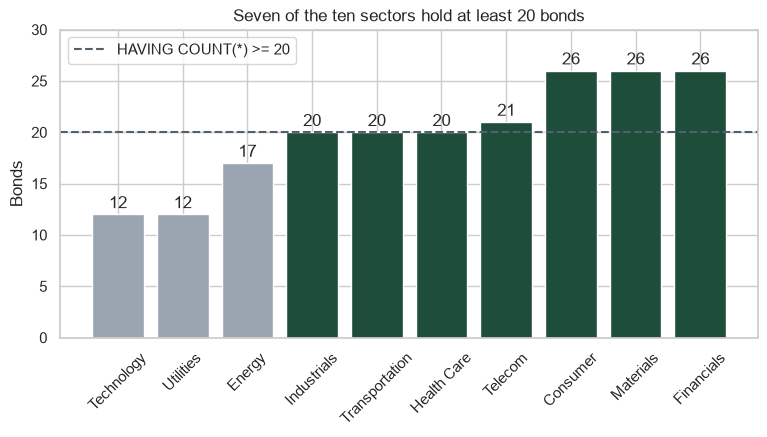

In [27]:
# bonds per sector, fewest first; the sectors HAVING kept in dark green
counts = counts.sort_values('bonds')
colours = ['#1E4D3A' if bonds >= 20 else '#9AA5B1' for bonds in counts['bonds']]
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(counts['sector'], counts['bonds'], color=colours)
ax.bar_label(bars, padding=2)
ax.axhline(20, color='#52606D', linestyle='--', label='HAVING COUNT(*) >= 20')
ax.set_ylim(0, 30)
ax.tick_params(axis='x', rotation=45)
ax.set_title('Seven of the ten sectors hold at least 20 bonds')
ax.set_ylabel('Bonds')
ax.legend(loc='upper left')
plt.show()

**Excel side by side.** `=FILTER(J2:K11,K2:K11>=20)` on the summary block, its counts in K, returns the same 7 sectors.

**Predict 2**

Q. Move the count test into `WHERE`: `WHERE COUNT(*) >= ?`. What comes back?

A) the same 7 sectors
B) an error
C) all 10 sectors

In [28]:
# the count test moved into WHERE
sql = 'SELECT sector, COUNT(*) AS bonds FROM holdings WHERE COUNT(*) >= ? GROUP BY sector'
md.run_query(db_path, sql, (20,))

DatabaseError: Execution failed on sql 'SELECT sector, COUNT(*) AS bonds FROM holdings WHERE COUNT(*) >= ? GROUP BY sector': misuse of aggregate: COUNT()

![Eight invented bonds in three sectors flow down. WHERE oas > 200 greys out the rows that fail, one row at a time. GROUP BY collapses the rest into three sectors with their counts. HAVING, a count of at least 2, greys out a sector whose count is too small. Beside it, the written order: SELECT, FROM, WHERE, GROUP BY, HAVING, ORDER BY, LIMIT](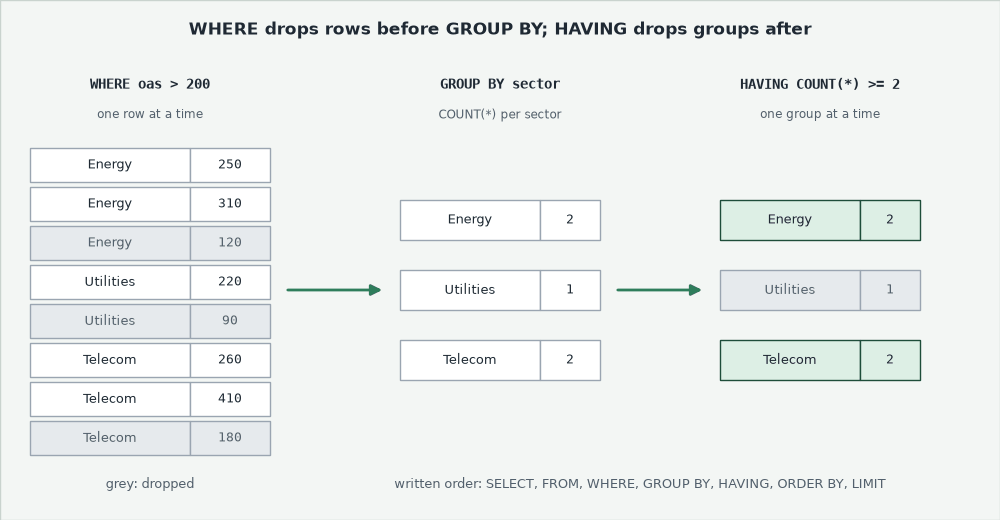)

B.
`WHERE` tests one row at a time, before the grouping, and a single row has no count.
`HAVING` runs after `GROUP BY`, so it filters groups.

### Both Filters

Q. Which sectors hold at least 7 bonds wider than 200 bp?

In [29]:
# WHERE drops the rows first, then HAVING drops the groups
sql = '''SELECT sector, COUNT(*) AS bonds FROM holdings WHERE oas > ?
         GROUP BY sector HAVING COUNT(*) >= ? ORDER BY sector'''
both = md.run_query(db_path, sql, (200, 7))
wide = holdings[holdings['oas'] > 200].groupby('sector').agg(bonds=('cusip', 'count'))
wide = wide.reset_index()
md.assert_same_rows(both, wide[wide['bonds'] >= 7], sort_by=['sector'])
both

,sector,bonds
0,Consumer,8
1,Industrials,9
2,Materials,7
3,Telecom,8


**Excel side by side.** `=COUNTIFS($C$2:$C$201,J2,$E$2:$E$201,">200")` counts with two tests: 3 for Energy, the three bonds `WHERE` found.

### Two Tests

The first proves the order does not matter, the second that a difference is caught.
`as_index=False` in the first keeps `sector` as a column, as `.reset_index()` does.

In [30]:
%%writefile -a test_marketdata.py


def test_assert_same_rows_ignores_order(tmp_path):
    db_path = build_database(tmp_path)
    sql_result = md.run_query(db_path, "SELECT sector, COUNT(*) AS bonds, SUM(market_value) AS market_value "
                                       "FROM holdings GROUP BY sector ORDER BY market_value DESC")
    holdings = pd.read_csv(HERE / "holdings.csv")
    pandas_result = (holdings.groupby("sector", as_index=False)
                     .agg(market_value=("market_value", "sum"), bonds=("cusip", "count")))
    # different row order and column order, the same rows
    md.assert_same_rows(sql_result, pandas_result, sort_by=["sector"])


def test_assert_same_rows_catches_difference():
    left = pd.DataFrame({"sector": ["Energy", "Utilities"], "bonds": [20, 15]})
    right = pd.DataFrame({"sector": ["Utilities", "Energy"], "bonds": [15, 21]})
    with pytest.raises(AssertionError):
        md.assert_same_rows(left, right, sort_by=["sector"])
    with pytest.raises(AssertionError):
        md.assert_same_rows(left, left.rename(columns={"bonds": "count"}), sort_by=["sector"])

Appending to test_marketdata.py


In [31]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..............................................                           [100%]
46 passed in 0.50s



**`WHERE` filters rows, `HAVING` filters groups, and the sector summary ties to pandas and to Excel's pivot table.**

## 11.7 A Market-Value Weighted Average in SQL

`AVG(oas)` gives every bond the same say, 250,000 face and 5,000,000 face alike.
The desk weights by market value, as Course 2's `bondmath.weighted_average` does: the sum of OAS times weight over the sum of the weights.

### By Sector, Against `bondmath`

In [32]:
# by sector: OAS weighted by market value, and the simple average, in bp
sql = '''SELECT sector, SUM(oas * market_value) / SUM(market_value) AS weighted_oas,
                AVG(oas) AS avg_oas
         FROM holdings GROUP BY sector'''
weighted_sql = md.run_query(db_path, sql)
# the twin: notebook 03's loop over groups, each sector through bondmath
rows = []
for sector, bonds in holdings.groupby('sector'):
    rows.append({'sector': sector, 'avg_oas': bonds['oas'].mean(),
                 'weighted_oas': bondmath.weighted_average(bonds['oas'], bonds['market_value'])})
from_bondmath = pd.DataFrame(rows)
md.assert_same_rows(weighted_sql, from_bondmath, sort_by=['sector'])

**Excel side by side.** In the summary block, sector in J2:

<table align="left">
<tr><th align="left">Job</th><th align="left">SQL</th><th align="left">pandas</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Weighted OAS by sector</td><td align="left"><code>SUM(oas * market_value) / SUM(market_value)</code></td><td align="left"><code>bondmath.weighted_average</code></td><td align="left"><code>=SUMPRODUCT(($C$2:$C$201=J2)*$E$2:$E$201*$F$2:$F$201)/SUMIFS($F$2:$F$201,$C$2:$C$201,J2)</code></td><td align="left">Energy 176.34941368150737, all ten equal</td></tr>
</table>
<br clear="left">

The sector test gives TRUE or FALSE per row, and multiplied they count as 1 and 0, so only the sector's bonds add up.

### Weighted Against Simple

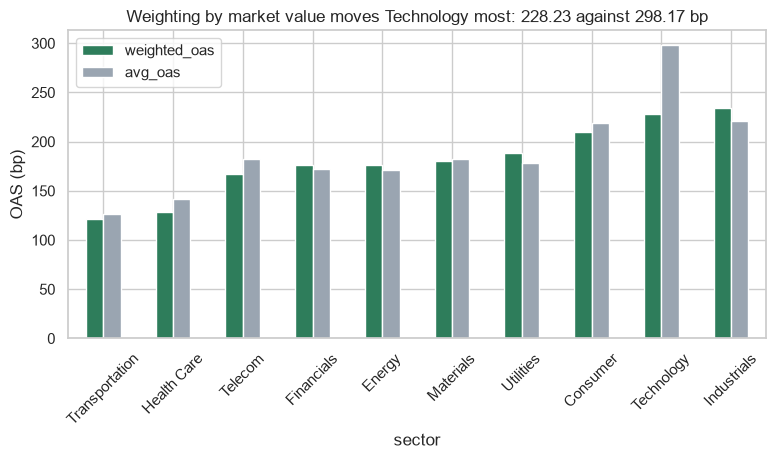

In [33]:
# each sector's two averages side by side, in bp; y= with a list draws a bar for each column
chart = weighted_sql.sort_values('weighted_oas').plot.bar(
    x='sector', y=['weighted_oas', 'avg_oas'], figsize=(9, 4), rot=45, ylabel='OAS (bp)',
    title='Weighting by market value moves Technology most: 228.23 against 298.17 bp')
plt.show()

### The Book in One Row

In [34]:
# no GROUP BY: the whole book is one group
sql = '''SELECT SUM(oas * market_value) / SUM(market_value) AS weighted_oas,
                AVG(oas) AS avg_oas
         FROM holdings'''
book_sql = md.run_query(db_path, sql)
book_weighted = bondmath.weighted_average(holdings['oas'], holdings['market_value'])
print(f"SQL {book_sql.loc[0, 'weighted_oas']} bp, bondmath {book_weighted} bp")
print(f"simple average {book_sql.loc[0, 'avg_oas']} bp")

SQL 180.4609519769922 bp, bondmath 180.4609519769922 bp
simple average 185.75 bp


180.46 bp is the spread on Course 2's risk card, in Portfolio Aggregation and Scenarios.
Course 1's Combining and Loading, Part 2 printed the same pair: simple 185.75, weighted 180.46.

**Predict 3**

Q. Weight the book by face held instead: `SUM(oas * par_held) / SUM(par_held)`. What does the query return, in bp? Write down a number.

### Weighted by Face

In [35]:
# the weights are now face held, in dollars
sql = 'SELECT SUM(oas * par_held) / SUM(par_held) AS weighted_oas FROM holdings'
by_face = md.run_query(db_path, sql)
face_bondmath = bondmath.weighted_average(holdings['oas'], holdings['par_held'])
print(f"SQL {by_face.loc[0, 'weighted_oas']} bp, bondmath {face_bondmath} bp")
assert abs(by_face.loc[0, 'weighted_oas'] - face_bondmath) < 1e-9, 'SQL and bondmath disagree'

SQL 184 bp, bondmath 184.51789366053168 bp


AssertionError: SQL and bondmath disagree

### Whole Numbers Divide as Whole Numbers

In [36]:
# the same division, with a whole number and with a decimal on the bottom
md.run_query(db_path, 'SELECT 7 / 2 AS whole, 7 / 2.0 AS decimal')

,whole,decimal
0,3,3.5


`oas` and `par_held` are whole numbers in the file, so SQLite keeps them whole, and a division of whole numbers drops the remainder.
`market_value` has cents, so its whole column is stored as decimals, and the market-value weights came out right.
`* 1.0` turns the top into a decimal before the division.

In [37]:
# * 1.0 makes the top a decimal
sql = 'SELECT SUM(oas * par_held) * 1.0 / SUM(par_held) AS weighted_oas FROM holdings'
fixed = md.run_query(db_path, sql)
assert abs(fixed.loc[0, 'weighted_oas'] - face_bondmath) < 1e-9
print(f"SQL {fixed.loc[0, 'weighted_oas']} bp, bondmath {face_bondmath} bp")

SQL 184.51789366053168 bp, bondmath 184.51789366053168 bp


The division ran with no error and no warning; only the twin caught it.

**The book's market-value weighted OAS is 180.46 bp in SQL and in `bondmath`; a division of whole numbers drops the decimals without a word, and only the twin catches it.**

## 11.8 Commit the Queries, Not the Database

The note's last two asks: keep the queries where anyone can rerun them, and keep the database out of Git.

### Is the Database Ignored?

In [38]:
# -v names the .gitignore line that matches
!git -C "{work}" check-ignore -v course3.db

.gitignore:5:*.db	course3.db


Notebook 01's `*.db` line: any database file stays out of the record.

### The Day's Queries in One File

`--` starts an SQL comment, and `;` ends each query.

In [39]:
%%writefile queries.sql
-- queries.sql: the day 11 queries on the course's synthetic book. Values go in as ? parameters.

-- four columns of every bond
SELECT cusip, issuer, sector, oas FROM holdings;

-- WHERE: one sector, spreads above a level (parameters: 'Energy', 200)
SELECT cusip, issuer, oas FROM holdings WHERE sector = ? AND oas > ?;

-- ORDER BY and LIMIT: the largest positions by market value (parameter: 5)
SELECT cusip, issuer, market_value FROM holdings ORDER BY market_value DESC LIMIT ?;

-- dates are ISO text, so < compares in date order (parameter: '2030-01-01')
SELECT cusip, issuer, maturity FROM holdings WHERE maturity < ? ORDER BY maturity;

-- GROUP BY: bonds, market value in dollars, and simple average OAS in bp by sector
SELECT sector, COUNT(*) AS bonds, SUM(market_value) AS market_value, AVG(oas) AS avg_oas
FROM holdings GROUP BY sector ORDER BY market_value DESC;

-- HAVING: sectors with at least this many bonds (parameter: 20)
SELECT sector, COUNT(*) AS bonds FROM holdings GROUP BY sector HAVING COUNT(*) >= ? ORDER BY sector;

-- market-value weighted OAS in bp by sector
SELECT sector, SUM(oas * market_value) / SUM(market_value) AS weighted_oas, AVG(oas) AS avg_oas
FROM holdings GROUP BY sector;

Writing queries.sql


### What Git Sees

In [40]:
# every file Git sees, the ignored ones too
!git -C "{work}" status --short --ignored
!git -C "{work}" diff --stat

 M marketdata.py
 M test_marketdata.py
?? queries.sql
!! __pycache__/
!! benchmark.csv
!! bondmath.py
!! course3.db
!! course3_excel_reference.csv
!! course3_fred_format_dgs10.json
!! course3_fred_format_dgs2.json
!! course3_synthetic_spreads.csv
!! holdings.csv
!! issuers.csv
!! ratings.csv
!! trade_blotter.csv
!! treasury_par_yields.csv
 marketdata.py      | 62 ++++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_marketdata.py | 48 ++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 110 insertions(+)


` M`: the module and the tests changed, 110 lines added.
`??`: `queries.sql` is new.
`!!`: left out of Git.
`course3.db` by the `.gitignore` line, the data files and `bondmath.py` by the work folder's own ignore list, as in Course 2's Treasury Curve Interpolation.

### Commit Three Files by Name

In [41]:
# the three files by name, the day's subject, and what the commit holds
!git -C "{work}" add marketdata.py test_marketdata.py queries.sql
!git -C "{work}" commit -m "Notebook 11: load_tables, run_query, assert_same_rows, and queries.sql"
!git -C "{work}" show --stat --oneline HEAD

[main fb9ff0f] Notebook 11: load_tables, run_query, assert_same_rows, and queries.sql
 3 files changed, 134 insertions(+)
 create mode 100644 queries.sql
fb9ff0f Notebook 11: load_tables, run_query, assert_same_rows, and queries.sql
 marketdata.py      | 62 ++++++++++++++++++++++++++++++++++++++++++++++++++++++
 queries.sql        | 24 +++++++++++++++++++++
 test_marketdata.py | 48 ++++++++++++++++++++++++++++++++++++++++++
 3 files changed, 134 insertions(+)


**The record holds the code, the tests and the queries; one call to `load_tables` rebuilds the database, so it is never committed.**

## Bring It Home

Copy the work folder's `marketdata.py`, `test_marketdata.py` and `queries.sql` into your own `my_bondmath` folder, with the two files the new tests read, test them there, and commit.
The copy replaces your files of those names, so anything of your own must be in the work folder first.
In a PowerShell terminal in VS Code, with the course's `.venv` active:

```powershell
# the work folder: use the name your setup cell printed
$work = "$env:TEMP\pfi_course3_11_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\marketdata.py", "$work\test_marketdata.py", "$work\queries.sql" .
Copy-Item "$work\holdings.csv", "$work\ratings.csv" .
python -m pytest -q test_marketdata.py
git status --short
git add marketdata.py test_marketdata.py queries.sql
git commit -m "Notebook 11: load_tables, run_query, assert_same_rows, and queries.sql"
```

pytest shows 46 passed.
`git status` lists the two data files as new: course data is never committed, so stage the three files by name.
In Colab, download the three files from the work folder under `/tmp` instead.
The work folder stays in your temp folder; the system clears it in time.

## You Can Now

By the end of this notebook, you can:

* Put CSV files into a SQLite database file with `load_tables`, every row count checked.
* Ask with `SELECT`, `WHERE`, `ORDER BY` and `LIMIT`, and prove each answer against pandas with `assert_same_rows`.
* Pass every value as a `?` parameter, and say what SQL injection is.
* Summarise with `GROUP BY`, `COUNT`, `SUM` and `AVG`, and filter groups with `HAVING`.
* Write a weighted average in SQL, and catch a division of whole numbers with a twin.
* Commit the queries and keep the database out of Git.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Every SQL answer gets a pandas twin and `md.assert_same_rows`.
Replace each `...` with your own code, then run the check cell under it.
Run the next cell first: it defines `check`.

In [42]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

Q. Face held (`par_held`, in dollars) by rating bucket.
The bucket sits in the `ratings` table, so the query needs one new line after `FROM holdings`.
`JOIN ratings ON holdings.rating = ratings.rating` gives each bond the `ratings` row with the same rating, as Course 1's `pd.merge(holdings, ratings, on='rating')` does.
Group by `bucket` with `SUM(par_held) AS face`, check against pandas, and store the BBB bucket's face in **ex1_bbb_face**.

In [43]:
ex1_bbb_face = ...

In [44]:
check('Exercise 1 BBB face', ex1_bbb_face, 151750000)

Exercise 1 BBB face: not attempted yet


### Exercise 2

Q. The ten widest bonds by OAS with their issuers: `cusip`, `issuer`, `oas`, widest first.
`ORDER BY oas DESC, cusip` breaks a tie on OAS by cusip, so the cut is always the same.
Check the rows with `md.assert_same_rows` and the order with a second assert, then store the ten cusips, in order, as a list, in **ex2_cusips**.

In [45]:
ex2_cusips = ...

In [46]:
check('Exercise 2 the ten widest', ex2_cusips,
      ['99069RAC4', '99009JAA9', '99038MAE9', '99066OAB6', '99066OAD2',
       '99038MAH2', '99088KAH5', '99069RAD2', '99036KAA3', '99049XAE2'])

Exercise 2 the ten widest: not attempted yet


### Exercise 3

Q. Add `count_by(db_path, table, column)` to the module, docstring first, and a test for it:

* `count_by` returns one row per value of `column` in `table`, with the columns `column` and `row_count`, sorted by the value, counted with SQL through `run_query`.
* A table or column name cannot be a `?`, so it raises `ValueError` unless each name passes `str.isidentifier()`.
* `test_count_by_matches_pandas` checks, on `build_database(tmp_path)`, that the counts by sector equal pandas' and that a column name with SQL in it raises `ValueError`.

Run pytest, reload, and store the Energy count from `md.count_by(db_path, 'holdings', 'sector')` in **ex3_energy**.

In [47]:
%%writefile -a marketdata.py


# Exercise 3: write count_by(db_path, table, column) below this line

Appending to marketdata.py


In [48]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_count_by_matches_pandas(tmp_path) below this line

Appending to test_marketdata.py


In [49]:
# run pytest as in the lesson, reload the module, then call your function
ex3_energy = ...

In [50]:
check('Exercise 3 Energy bonds', ex3_energy, 17)

Exercise 3 Energy bonds: not attempted yet


### Exercise 4: AI check

You asked an assistant for the book's market-value weighted OAS by grade, with the docstring below as the prompt.
The function below came back, written for this course in the style of an assistant's answer; it runs, returns believable numbers, and holds one bug.
Its `JOIN` line is right: Exercise 1's.

In [51]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def weighted_oas_by_grade(db_path):
    """Market-value weighted OAS of the book by grade, in basis points.

    Units: OAS in bp; the weights are market values in dollars. Convention: one row per grade,
    with the columns grade, bonds, and oas_bp, where oas_bp is
    sum(oas x market_value) / sum(market_value) over the grade's bonds,
    the same number bondmath.weighted_average gives.
    """
    sql = '''SELECT grade, COUNT(*) AS bonds, AVG(oas) AS oas_bp
             FROM holdings
             JOIN ratings ON holdings.rating = ratings.rating
             GROUP BY grade ORDER BY grade'''
    return md.run_query(db_path, sql)


weighted_oas_by_grade(db_path)

,grade,bonds,oas_bp
0,High Yield,72,339.375000
1,Investment Grade,128,99.335938


Q. Read the `SELECT` line against the docstring, then test the function before you trust it, with `bondmath.weighted_average` as the answer key.

In [52]:
# the test, from the docstring: each grade against bondmath
result = weighted_oas_by_grade(db_path).set_index('grade')
graded = pd.merge(holdings, pd.read_csv('ratings.csv'), on='rating')
for grade, bonds in graded.groupby('grade'):
    query_bp = result.loc[grade, 'oas_bp']
    expected = bondmath.weighted_average(bonds['oas'], bonds['market_value'])
    message = f'{grade}: {query_bp:.4f} bp from the query, {expected:.4f} from bondmath'
    assert abs(query_bp - expected) < 1e-9, message
print('Both grades equal bondmath.weighted_average')

AssertionError: High Yield: 339.3750 bp from the query, 334.7313 from bondmath

Q. Fix the query in the function's cell and run the test again until it passes.
Store the fixed function's Investment Grade `oas_bp` in **ex4_ig** and its High Yield `oas_bp` in **ex4_hy**.

In [53]:
ex4_ig = ...
ex4_hy = ...

In [54]:
check('Exercise 4 Investment Grade', ex4_ig, 98.78627910957701)
check('Exercise 4 High Yield', ex4_hy, 334.7313192734511)

Exercise 4 Investment Grade: not attempted yet
Exercise 4 High Yield: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Energy wider than 200 bp</td><td align="left">3 bonds, the same in SQL, pandas and Excel</td></tr>
<tr><td align="left">The five largest positions</td><td align="left">Bezane Finance first, 5,435,500.00 dollars</td></tr>
<tr><td align="left">Each sector's bonds, market value and average spread</td><td align="left">10 sectors, 200 bonds, 490,819,215.00 dollars, tied to the pivot table</td></tr>
<tr><td align="left">At least 20 bonds</td><td align="left">7 sectors</td></tr>
<tr><td align="left">Spread weighted by market value</td><td align="left">180.46 bp, equal to <code>bondmath</code></td></tr>
<tr><td align="left">The queries</td><td align="left"><code>queries.sql</code> committed, <code>course3.db</code> ignored</td></tr>
</table>
<br clear="left">

Be proud: you learned a new language today and never once took it on trust.

Next: SQL Joins and Time Series (notebook 12), where the tables meet and every join is counted.